# Figure 3 Supplement 3: The stopping model captures apparently suboptimal behavior

Two features of the direct bound measures look like departures from an ideal
bound-crossing process (both defined in `pigeon.data.get_crossing_diagnostics`,
at the commit step inferred by `get_bounds`):

- **Incongruent choice:** the choice is opposite to the side the pigeon was on
  at the inferred commit (sign of the midpoint of the positions at DT − 1 and
  DT).
- **Premature crossing:** the pigeon had already been at or beyond the measured
  bound on that side before the inferred commit, without the subject
  committing.

**A, B** — the fraction of trials with each feature vs. the measured |bound|,
data (black; mean ± SEM across subjects) and the stopping model (dashed blue;
each subject simulated `SIM_REPS` times from their fit and measured with the
same pipeline). **C** — what produces these trials in the model
(`pigeon.stopping.get_commit_sources`): a guess or anticipation instead of a bound crossing; a
lapse (random choice); timing (the pipeline's assumed NDT placed the commit at
the wrong step); sensory noise (the perceived position crossed the bound but
the on-screen position had not, on that side); measurement error (the pigeon crossed
zero between DT − 1 and DT, so the midpoint used by the measures can fall on
the other side); or the collapsing bound (none of the above: the pigeon had been
farther out earlier, when the bound was still higher). Each simulated trial
gets the first source that applies, in that order.

Columns: OL low-SNR blocks 1–3 (no-penalty, coin-penalty and step-penalty
conditions), as in the other Figure 3 supplements. Trials: those the model was fit to
(`get_stopping_model_trials`: trial_number ≥ 10, with a choice) that pass the standard
filter (`get_good_trial_array`: DT ≥ 2, no wall hit, RT cutoff); raw positions (no bias correction) for both
data and model. All subject-blocks are included.

In [1]:
import sys
sys.path.insert(0, '..')


import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import numpy as np
import pandas as pd

from pigeon.data import get_crossing_diagnostics, get_good_trial_array
from pigeon.pathDefaults import DATA_DIR, FIGURES_DIR
from pigeon.plotting import (CM, FS_INSET, CONDITION_LABELS, DATA_COLOR, MODEL_COLOR, add_panel_label,
                             add_row_xlabel, use_figure_style)
from pigeon.stopping import (COMMIT_SOURCES, get_commit_sources, get_stopping_model_trials, infer_bounds_like_data,
                             simulate_stopping_data_table)

PROCESSED = DATA_DIR

In [2]:
SIM_REPS = 5
SIM_SEED = 7
BLOCKS = ['B1', 'B2', 'B3']
BLOCK_TITLES = {f'B{b}': CONDITION_LABELS[b] for b in (1, 2, 3)}

# Simulate all six blocks (get_bounds estimates each subject's NDT and RT cutoffs from all of the
# subject's trials, as for the real data), then keep blocks 1-3.
trials_all = get_stopping_model_trials('OL', [1, 2, 3, 4, 5, 6])
fits = pd.read_pickle(PROCESSED / 'stopping_fits_main.pkl')
fits = fits[fits.task == 'OL']
sim = simulate_stopping_data_table(trials_all, fits, group_col='condition', num_reps=SIM_REPS,
                                   rng=np.random.default_rng(SIM_SEED))
sim = infer_bounds_like_data(sim).assign(trial_number=99)

def _diagnosed(t):
    t = t[t.condition.isin(BLOCKS) & get_good_trial_array(t, min_dt=2)].copy()
    t[['incongruent', 'premature_crossing']] = get_crossing_diagnostics(t).values
    return t

real, model = _diagnosed(trials_all), _diagnosed(sim)
model['source'] = get_commit_sources(model)
for name, t in (('data', real), ('model', model)):
    undefined = t[['incongruent', 'premature_crossing']].isna().any(axis=1)
    print(f'{name}: {len(t):,} trials pass the filter; {int(undefined.sum())} with an undefined statistic '
          f'(zero midpoint), left out')

OL: subjects with a good adaptation tau fit, by block: {1: 2, 2: 25, 3: 9, 4: 18, 5: 8, 6: 9}
OL: 42,252 trials in blocks [1, 2, 3, 4, 5, 6]; excluded 3,240 with trial_number < 10, 225 more in the adaptation transient, 364 more with no choice; 60 subjects


data: 7,776 trials pass the filter; 0 with an undefined statistic (zero midpoint), left out
model: 38,685 trials pass the filter; 0 with an undefined statistic (zero midpoint), left out


In [3]:
BIN_WIDTH = 0.1
MAX_BOUND = 0.6
MIN_TRIALS = 5     # per subject and bin
MIN_SUBJECTS = 3   # per bin

def _binned(t, col):
    # Mean +/- SEM across subjects of each subject's fraction per |bound| bin.
    t = t.dropna(subset=[col])
    t = t[t.abs_bound < MAX_BOUND].assign(_bin=lambda d: np.floor(d.abs_bound / BIN_WIDTH))
    per_subj = t.groupby(['subject_index', '_bin'])[col].agg(['mean', 'size'])
    per_subj = per_subj[per_subj['size'] >= MIN_TRIALS]['mean']
    g = per_subj.groupby(level='_bin').agg(['mean', 'sem', 'size'])
    g = g[g['size'] >= MIN_SUBJECTS]
    return (g.index.to_numpy() + 0.5) * BIN_WIDTH, g['mean'].to_numpy(), g['sem'].to_numpy()

rates = pd.DataFrame({(name, col): t.groupby('condition')[col].mean()
                      for name, t in (('data', real), ('model', model))
                      for col in ('incongruent', 'premature_crossing')})
print('Overall fraction of trials:')
display(rates.round(3))
sources = {col: pd.crosstab(model[model[col] == 1].condition, model[model[col] == 1].source, normalize='index')
           .reindex(columns=list(COMMIT_SOURCES), fill_value=0.0) for col in ('incongruent', 'premature_crossing')}
for col, tab in sources.items():
    print(f'Model sources of {col} trials (fractions):')
    display(tab.round(3))

Overall fraction of trials:


data                          model                   
          incongruent premature_crossing incongruent premature_crossing
condition                                                              
B1              0.100              0.130       0.113              0.120
B2              0.073              0.161       0.076              0.168
B3              0.048              0.167       0.057              0.162

Model sources of incongruent trials (fractions):


source,guess,lapse,timing,sensory noise,measurement,collapsing bound
condition,,,,,,
B1,0.294,0.412,0.099,0.186,0.010,0.0
B2,0.261,0.505,0.117,0.105,0.011,0.0
B3,0.150,0.439,0.201,0.201,0.010,0.0


Model sources of premature_crossing trials (fractions):


source,guess,lapse,timing,sensory noise,measurement,collapsing bound
condition,,,,,,
B1,0.193,0.077,0.194,0.274,0.038,0.224
B2,0.157,0.064,0.245,0.269,0.032,0.232
B3,0.087,0.050,0.241,0.325,0.043,0.254


1 extra bytes in post.stringData array


'created' timestamp seems very low; regarding as unix timestamp


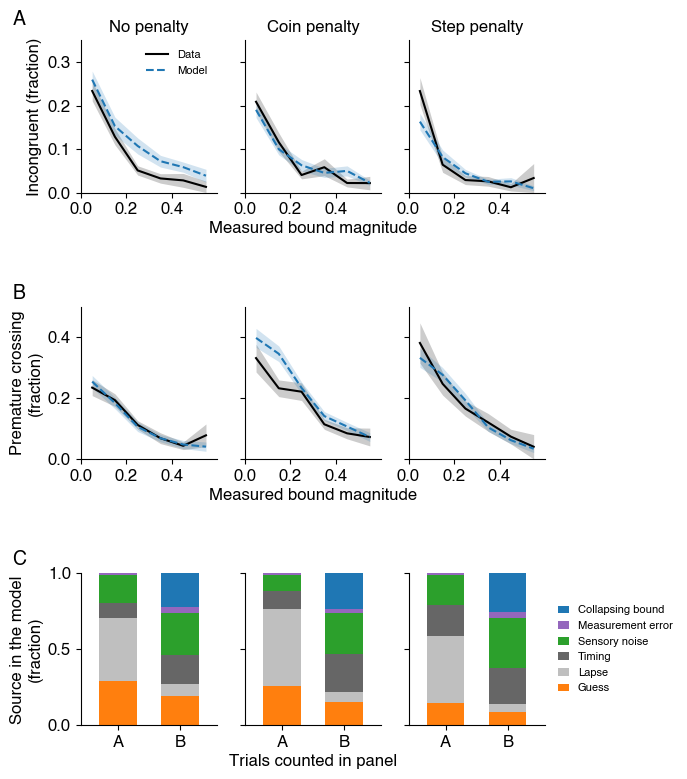

Saved /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Figures/Figure03_S03.pdf (+ .png)


In [4]:
use_figure_style()
SOURCE_COLORS = {'guess': 'tab:orange', 'lapse': '0.75', 'timing': '0.4', 'sensory noise': 'tab:green',
                 'measurement': 'tab:purple', 'collapsing bound': MODEL_COLOR}
SOURCE_LABELS = {'measurement': 'Measurement error'}

fig = plt.figure(figsize=(17.6 * CM, 20 * CM))
gs = gridspec.GridSpec(3, 3, figure=fig, hspace=0.75, wspace=0.2, left=0.13, right=0.8, bottom=0.08, top=0.95)
ax_inc = [fig.add_subplot(gs[0, i]) for i in range(3)]
ax_pre = [fig.add_subplot(gs[1, i]) for i in range(3)]
ax_src = [fig.add_subplot(gs[2, i]) for i in range(3)]

for bi, b in enumerate(BLOCKS):
    for ax, col, ylim in ((ax_inc[bi], 'incongruent', 0.35), (ax_pre[bi], 'premature_crossing', 0.5)):
        for t, color, ls, label in ((real, DATA_COLOR, '-', 'Data'), (model, MODEL_COLOR, '--', 'Model')):
            x, m, e = _binned(t[t.condition == b], col)
            ax.fill_between(x, m - e, m + e, color=color, alpha=0.2, lw=0)
            ax.plot(x, m, ls, color=color, lw=1.5, label=label)
        ax.set_xlim(0, MAX_BOUND)
        ax.set_ylim(0, ylim)
        ax.set_yticks(np.arange(0, ylim + 0.01, 0.1 if ylim < 0.4 else 0.2))
        ax.set_xticks([0, 0.2, 0.4])
        if bi > 0:
            ax.set_yticklabels([])
    ax_inc[bi].set_title(BLOCK_TITLES[b])

    ax = ax_src[bi]
    for xi, col in enumerate(('incongruent', 'premature_crossing')):
        bottom = 0.0
        for k in COMMIT_SOURCES:
            h = sources[col].loc[b, k]
            ax.bar(xi, h, bottom=bottom, color=SOURCE_COLORS[k], width=0.6, lw=0)
            bottom += h
    ax.set_xticks([0, 1])
    ax.set_xticklabels(['A', 'B'])   # the trials counted in rows A (incongruent) and B (premature crossing)
    ax.set_xlim(-0.6, 1.6)
    ax.set_ylim(0, 1)
    ax.set_yticks([0, 0.5, 1])
    if bi > 0:
        ax.set_yticklabels([])
ax_inc[0].set_ylabel('Incongruent (fraction)')
ax_pre[0].set_ylabel('Premature crossing\n(fraction)')
ax_src[0].set_ylabel('Source in the model\n(fraction)')
ax_inc[0].legend(fontsize=FS_INSET, frameon=False, loc='upper right')
for k in reversed(COMMIT_SOURCES):
    ax_src[2].bar(0, 0, color=SOURCE_COLORS[k], label=SOURCE_LABELS.get(k, k[0].upper() + k[1:]))
ax_src[2].legend(fontsize=FS_INSET, frameon=False, loc='center left', bbox_to_anchor=(1.02, 0.5), handlelength=1)

add_row_xlabel(fig, ax_inc, 'Measured bound magnitude')
add_row_xlabel(fig, ax_pre, 'Measured bound magnitude')
add_row_xlabel(fig, ax_src, 'Trials counted in panel')
for ax in ax_inc + ax_pre + ax_src:
    ax.spines[['top', 'right']].set_visible(False)
add_panel_label(ax_inc[0], 'A', dx=-0.5, dy=1.2)
add_panel_label(ax_pre[0], 'B', dx=-0.5, dy=1.15)
add_panel_label(ax_src[0], 'C', dx=-0.5, dy=1.15)

out = FIGURES_DIR / 'Figure03_S03.pdf'
fig.savefig(out, dpi=300, bbox_inches='tight')
fig.savefig(out.with_suffix('.png'), dpi=300, bbox_inches='tight')
plt.show()
print(f'Saved {out} (+ .png)')